In [1]:
%reset
import numpy as np
import matplotlib.pyplot as plt
import dnaMD
import fileinput as fi
from pylab import *
%matplotlib inline

def rm_neun(vari):
    indizes = np.array([])
    for x in range(len(vari)):
        nmmr = np.where(vari[x] == 99.99)
        indizes = np.append(indizes,nmmr)

    indexes = np.sort(indizes)
    indexes = np.flip(indexes)
    indexes = indexes.astype(int)
    indexes = list(dict.fromkeys(indexes))
       
    for d in range(len(vari)):
        for y in range(len(indexes)):
            #print(indexes[y])
            vari[d] = np.delete(vari[d],indexes[y])
            
    return vari

Once deleted, variables cannot be recovered. Proceed (y/[n])? y



Reading file : PCA/DNA/erstePCA/L-BPH_g.dat
Reading frame 90
Finished reading.... Total number of frame read =  100

Reading file : PCA/DNA/erstePCA/HelixRad_g.dat
Reading frame 90
Finished reading.... Total number of frame read =  100

Reading file : PCA/DESRESeven/1_first/L-BPH_g.dat
Reading frame 90
Finished reading.... Total number of frame read =  100

Reading file : PCA/DESRESeven/1_first/HelixRad_g.dat
Reading frame 90
Finished reading.... Total number of frame read =  100

Reading file : ol3-odd-v2/L-BPH_ol3.dat
Reading frame 2000
Finished reading.... Total number of frame read =  2001

Reading file : ol3-odd-v2/HelixRad_ol3.dat
Reading frame 2000
Finished reading.... Total number of frame read =  2001


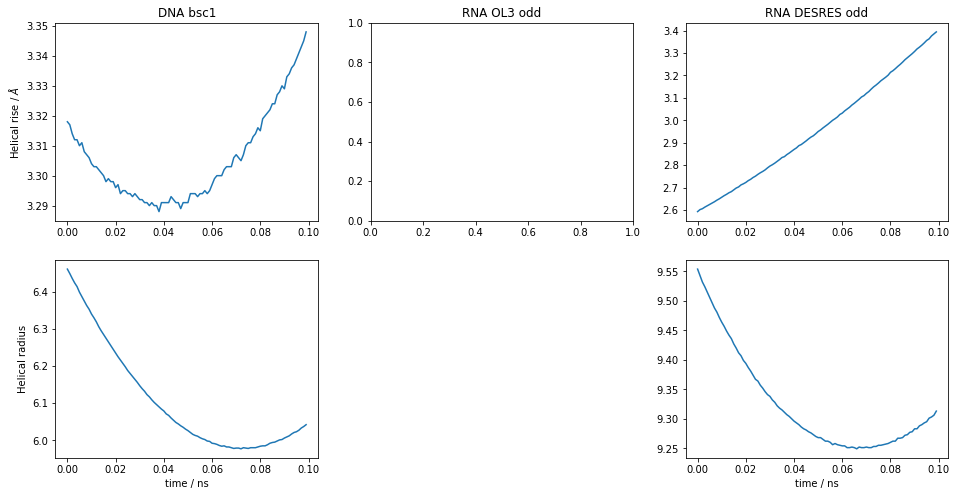

In [5]:
bscdna=dnaMD.DNA(20)
bscdna.set_base_step_parameters('PCA/DNA/erstePCA/L-BPH_g.dat',parameters='all',bp_step=[1, 19],step_range=True,helical=True) 
bscrad = dnaMD.DNA(20) 
bscrad.set_helical_radius('PCA/DNA/erstePCA/HelixRad_g.dat',atomname='C1*',bp=[1,19],bp_range=True)

Deodd=dnaMD.DNA(20)
Deodd.set_base_step_parameters('PCA/DESRESeven/1_first/L-BPH_g.dat',parameters='all',bp_step=[1, 19],step_range=True,helical=True) 
Deoddrad = dnaMD.DNA(20) 
Deoddrad.set_helical_radius('PCA/DESRESeven/1_first/HelixRad_g.dat',atomname='C1*',bp=[1,19],bp_range=True)


ol3odd = dnaMD.DNA(20); 
ol3oddrad = dnaMD.DNA(20)
ol3odd.set_base_step_parameters('ol3-odd-v2/L-BPH_ol3.dat',parameters='all',bp_step=[1, 19],step_range=True,helical=True) 
ol3oddrad.set_helical_radius('ol3-odd-v2/HelixRad_ol3.dat',atomname='C1*',bp=[1,19],bp_range=True)

rangen = [6,15]
Deoddrise, bp_idx = Deodd.get_parameters('h-rise',rangen,bp_range=True);avg_Deoddrise = np.mean(Deoddrise, axis=0)
Deoddtwist, bp_idx = Deodd.get_parameters('h-twist',rangen,bp_range=True);avg_Deoddtwist = np.mean(Deoddtwist, axis=0)
Deoddx, bp_idx = Deodd.get_parameters('x-disp',rangen,bp_range=True);#avg_Deoddx = np.mean(Deoddx, axis=0)
Deoddy, bp_idx = Deodd.get_parameters('y-disp',rangen,bp_range=True);#avg_Deoddy = np.mean(Deoddy, axis=0)
Deoddinc, bp_idx = Deodd.get_parameters('inclination',rangen,bp_range=True);#avg_Deoddinc = np.mean(Deoddinc, axis=0)
Deoddradius1, bp_idx = Deoddrad.get_parameters('radius s-1',rangen,bp_range=True); #avg_Deoddradius1 = np.mean(Deoddradius1, axis=0)
avg_Deoddradius1 = np.mean(Deoddradius1, axis=0)
 
bscdnarise, bp_idx = bscdna.get_parameters('h-rise',rangen,bp_range=True);avg_bscdnarise = np.mean(bscdnarise, axis=0)
bscdnatwist, bp_idx = bscdna.get_parameters('h-twist',rangen,bp_range=True);avg_bscdnatwist = np.mean(bscdnatwist, axis=0)
bscdnax, bp_idx = bscdna.get_parameters('x-disp',rangen,bp_range=True);#avg_bscdnax = np.mean(bscdnax, axis=0)
bscdnay, bp_idx = bscdna.get_parameters('y-disp',rangen,bp_range=True);#avg_bscdnay = np.mean(bscdnay, axis=0)
bscdnainc, bp_idx = bscdna.get_parameters('inclination',rangen,bp_range=True);#avg_bscdnainc = np.mean(bscdnainc, axis=0)
bscdnaradius1, bp_idx = bscrad.get_parameters('radius s-1',rangen,bp_range=True); 
avg_bscdnaradius1 = np.mean(bscdnaradius1, axis=0)

ol3oddrise, bp_idx = ol3odd.get_parameters('h-rise',rangen,bp_range=True); avg_ol3oddrise = np.mean(ol3oddrise, axis=0)
ol3oddtwist, bp_idx = ol3odd.get_parameters('h-twist',rangen,bp_range=True);avg_ol3oddtwist = np.mean(ol3oddtwist, axis=0)
ol3oddx, bp_idx = ol3odd.get_parameters('x-disp',rangen,bp_range=True);
ol3oddy, bp_idx = ol3odd.get_parameters('y-disp',rangen,bp_range=True);
ol3oddinc, bp_idx = ol3odd.get_parameters('inclination',rangen,bp_range=True);
ol3oddradius1, bp_idx = ol3oddrad.get_parameters('radius s-1',rangen,bp_range=True); 
avg_ol3oddradius1 = np.mean(ol3oddradius1, axis=0)






plt.figure(figsize=(16,8))
    
subplot(2,3,1)
plt.plot(bscdna.time/1000, avg_bscdnarise);plt.ylabel('Helical rise / $\AA$');
plt.title('DNA bsc1')
subplot(2,3,4)
plt.plot(bscdna.time/1000, avg_bscdnaradius1);plt.ylabel('Helical radius');plt.xlabel('time / ns');

subplot(2,3,2)
#plt.plot(ol3odd.time/1000, avg_ol3oddrise);plt.ylabel('Helical rise / $\AA$');
plt.title('RNA OL3 odd')
#subplot(2,3,5)
#plt.plot(ol3odd.time/1000, avg_ol3ddradius1);plt.ylabel('Helical twist / °');plt.xlabel('time / ns');

subplot(2,3,3)
plt.plot(Deodd.time/1000, avg_Deoddrise); 
plt.title('RNA DESRES odd')
subplot(2,3,6)
plt.plot(bscdna.time/1000, avg_Deoddradius1);plt.xlabel('time / ns');
